# Phase 9 — Explainable AI

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import shap
from pathlib import Path
from sklearn.model_selection import train_test_split

shap.initjs()
RANDOM_STATE = 42

PROC_DIR = Path('../data/processed')
MODELS_DIR = Path('../models')

purchase_pipeline = joblib.load(MODELS_DIR / 'purchase_prediction_model.pkl')
clv_pipeline = joblib.load(MODELS_DIR / 'clv_prediction_model.pkl')
rec_artifacts = joblib.load(MODELS_DIR / 'recommendation_artifacts.pkl')

print('Loaded purchase_prediction_model, clv_prediction_model, recommendation_artifacts')

c:\GUVI Projects\Intelligent-Ecommerce-Customer-Analytics\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded purchase_prediction_model, clv_prediction_model, recommendation_artifacts


## Rebuild the same train/test splits used in Phase 6 & 7

In [2]:
numeric_features = ['recency_days', 'frequency', 'monetary_value', 'avg_order_value',
                    'avg_basket_size', 'customer_tenure_days', 'avg_review_rating']
categorical_features = ['preferred_payment_method', 'customer_state_grouped']
feature_cols = numeric_features + categorical_features

# --- Purchase prediction (classification) ---
purchase_data = pd.read_csv(PROC_DIR / 'purchase_prediction_dataset.csv')
X_p = purchase_data[feature_cols]
y_p = purchase_data['repeat_purchase']
Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    X_p, y_p, test_size=0.2, random_state=RANDOM_STATE, stratify=y_p
)

# --- CLV prediction (regression) ---
clv_data = pd.read_csv(PROC_DIR / 'clv_prediction_dataset.csv')
X_c = clv_data[feature_cols]
y_c = clv_data['future_revenue']
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_c, y_c, test_size=0.2, random_state=RANDOM_STATE
)

print('Purchase test set:', Xp_test.shape, '| CLV test set:', Xc_test.shape)

Purchase test set: (6489, 9) | CLV test set: (6489, 9)


In [3]:
def make_predict_fn_transformed(pipeline, mode='proba'):
    """Explains the model on the ALREADY-PREPROCESSED numeric matrix (after
    one-hot encoding + scaling), not the raw mixed-type DataFrame. SHAP's
    perturbation/masking machinery does numeric operations (e.g. subtraction)
    on the background data - it can't do that on raw category strings like
    'credit_card' or 'SP', which is what causes a
    "unsupported operand type(s) for -: 'str' and 'str'" error if you feed it
    the raw DataFrame directly. Explaining the transformed space is also the
    standard way to pair SHAP with an sklearn Pipeline."""
    est_name = 'clf' if 'clf' in pipeline.named_steps else 'reg'
    estimator = pipeline.named_steps[est_name]
    preprocessor = pipeline.named_steps['preprocess']

    def transform(X_raw_df):
        X_t = preprocessor.transform(X_raw_df)
        return X_t.toarray() if hasattr(X_t, 'toarray') else X_t

    def predict_fn(X_transformed):
        if mode == 'proba':
            return estimator.predict_proba(X_transformed)[:, 1]
        return estimator.predict(X_transformed)

    return transform, predict_fn

## Purchase Prediction model — Feature Importance, SHAP Summary, Waterfall, Force

### Feature importance (model-native)

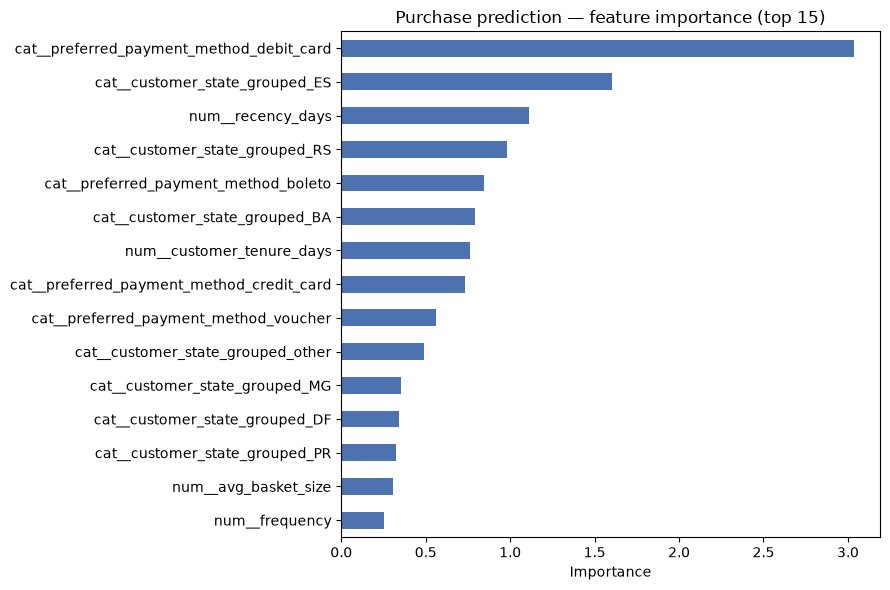

In [4]:
def get_feature_importance(pipeline, X_sample, y_sample, feature_cols):
    step_name = 'clf' if 'clf' in pipeline.named_steps else 'reg'
    est = pipeline.named_steps[step_name]
    feature_names = pipeline.named_steps['preprocess'].get_feature_names_out()

    if hasattr(est, 'feature_importances_'):
        importances = est.feature_importances_
    elif hasattr(est, 'coef_'):
        importances = np.abs(np.ravel(est.coef_))
    else:
        from sklearn.inspection import permutation_importance
        X_transformed = pipeline.named_steps['preprocess'].transform(X_sample)
        r = permutation_importance(est, X_transformed, y_sample, n_repeats=5, random_state=RANDOM_STATE)
        importances = r.importances_mean

    return pd.Series(importances, index=feature_names).sort_values(ascending=False)

purchase_importance = get_feature_importance(purchase_pipeline, Xp_test, yp_test, feature_cols)

fig, ax = plt.subplots(figsize=(9, 6))
purchase_importance.head(15).sort_values().plot(kind='barh', ax=ax, color='#4C72B0')
ax.set_title('Purchase prediction — feature importance (top 15)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

### SHAP setup

Uses SHAP's generic `Explainer`, which auto-selects an algorithm based on the
model type wrapped in `predict_fn` (fast `TreeExplainer` path for tree/boosting
models, permutation-based otherwise). Background and explain sets are kept
small for speed — increase if you want smoother summary plots and have time
to spare.

In [5]:
N_BACKGROUND = 100
N_EXPLAIN = 100

purchase_transform, purchase_predict_fn = make_predict_fn_transformed(purchase_pipeline, mode='proba')
purchase_feature_names = purchase_pipeline.named_steps['preprocess'].get_feature_names_out()

background_p_raw = Xp_train.sample(N_BACKGROUND, random_state=RANDOM_STATE)
explain_p_raw = Xp_test.sample(min(N_EXPLAIN, len(Xp_test)), random_state=RANDOM_STATE)

background_p = purchase_transform(background_p_raw)
explain_p = purchase_transform(explain_p_raw)

purchase_explainer = shap.Explainer(purchase_predict_fn, background_p, feature_names=purchase_feature_names)
purchase_shap_values = purchase_explainer(explain_p)
print('SHAP values computed for', purchase_shap_values.shape, '(customers x features)')

PermutationExplainer explainer: 101it [00:13,  7.21it/s]                        

SHAP values computed for (100, 22) (customers x features)


### SHAP Summary Plot (global view)

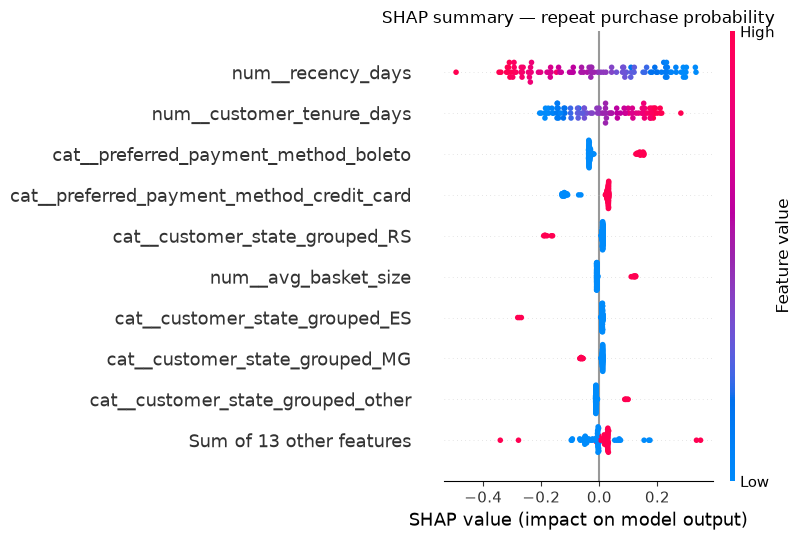

In [6]:
shap.plots.beeswarm(purchase_shap_values, show=False)
plt.title('SHAP summary — repeat purchase probability')
plt.tight_layout()
plt.show()

### SHAP Waterfall Plot — "Why is this customer likely to purchase again?"

Picks the customer in the explain set with the **highest predicted repeat-
purchase probability** and breaks down exactly which features pushed that
prediction up or down from the baseline.

Customer's predicted repeat-purchase probability: 88.38%
recency_days                        341
frequency                             2
monetary_value                   290.54
avg_order_value                  145.27
avg_basket_size                     1.0
customer_tenure_days                486
avg_review_rating                   5.0
preferred_payment_method    credit_card
customer_state_grouped               SP
Name: 10674, dtype: object


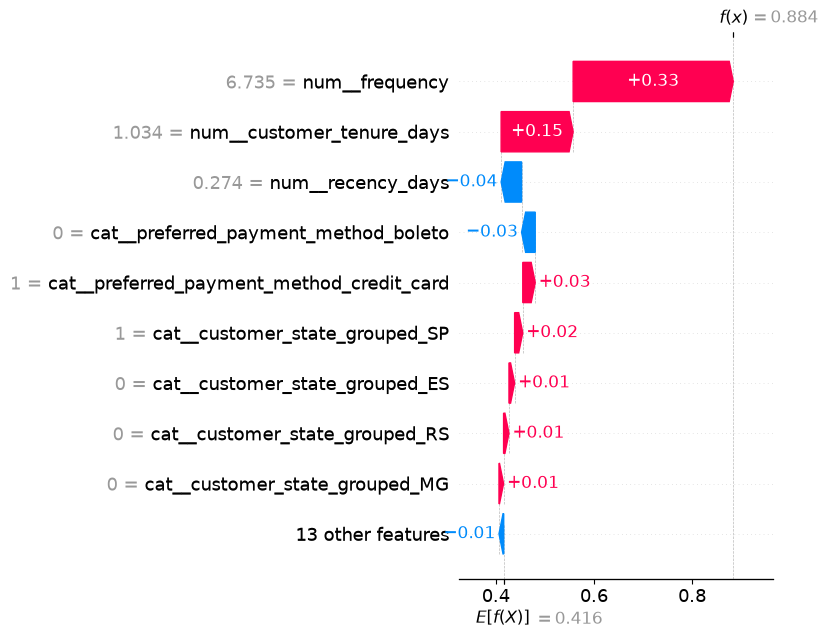

In [7]:
pred_probs = purchase_predict_fn(explain_p)
top_customer_pos = np.argmax(pred_probs)

print(f"Customer's predicted repeat-purchase probability: {pred_probs[top_customer_pos]:.2%}")
print(explain_p_raw.iloc[top_customer_pos])  # raw (human-readable) feature values

shap.plots.waterfall(purchase_shap_values[top_customer_pos], show=False)
plt.tight_layout()
plt.show()

### SHAP Force Plot (same customer, alternate view)

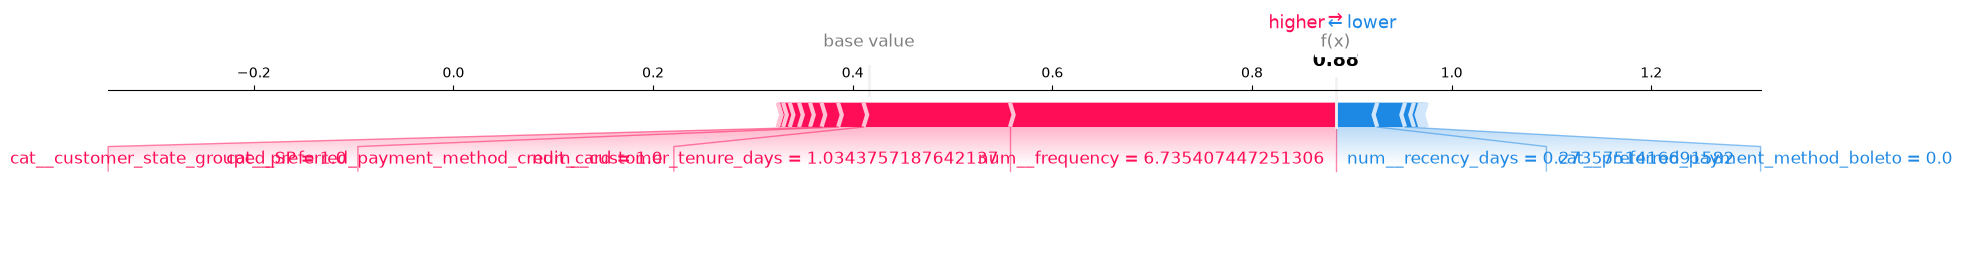

In [8]:
shap.plots.force(purchase_shap_values[top_customer_pos], matplotlib=True, show=False)
plt.tight_layout()
plt.show()

## CLV model — Feature Importance & SHAP Summary

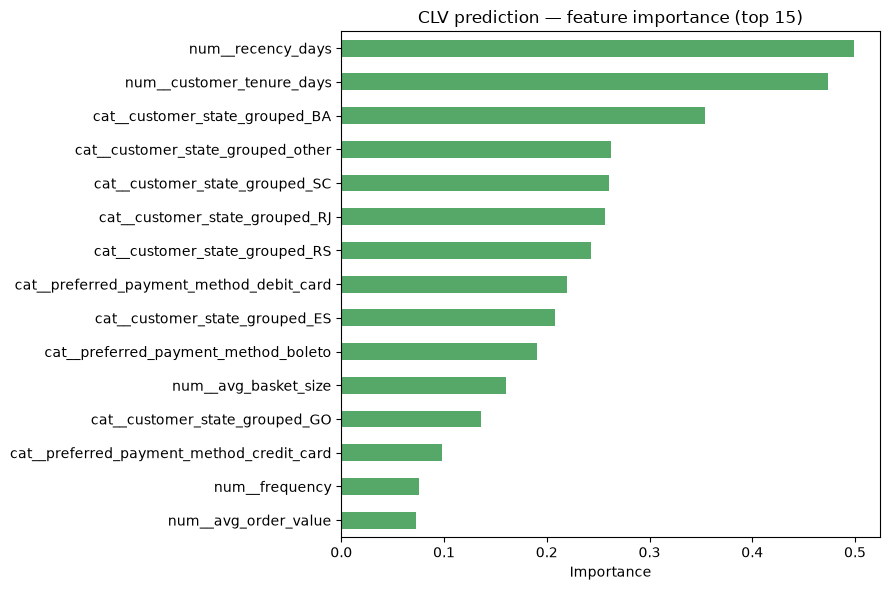

In [9]:
clv_importance = get_feature_importance(clv_pipeline, Xc_test, yc_test, feature_cols)

fig, ax = plt.subplots(figsize=(9, 6))
clv_importance.head(15).sort_values().plot(kind='barh', ax=ax, color='#55A868')
ax.set_title('CLV prediction — feature importance (top 15)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

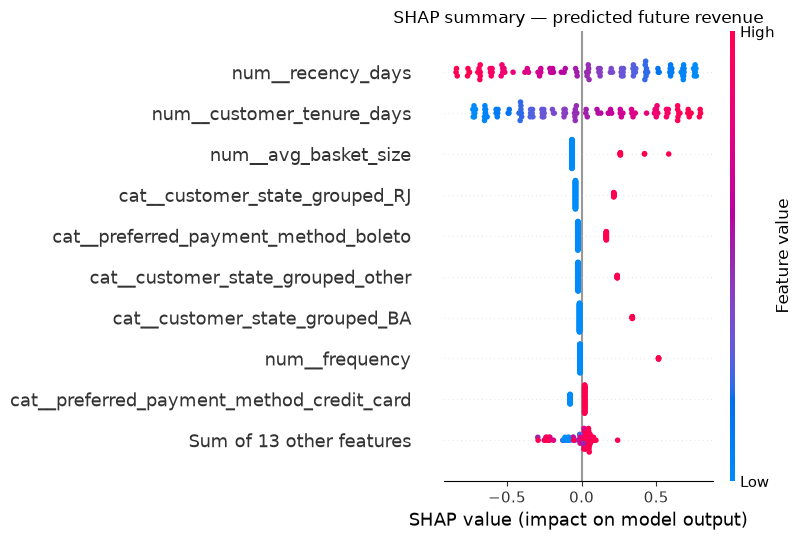

In [10]:
clv_transform, clv_predict_fn = make_predict_fn_transformed(clv_pipeline, mode='regression')
clv_feature_names = clv_pipeline.named_steps['preprocess'].get_feature_names_out()

background_c_raw = Xc_train.sample(N_BACKGROUND, random_state=RANDOM_STATE)
explain_c_raw = Xc_test.sample(min(N_EXPLAIN, len(Xc_test)), random_state=RANDOM_STATE)

background_c = clv_transform(background_c_raw)
explain_c = clv_transform(explain_c_raw)

clv_explainer = shap.Explainer(clv_predict_fn, background_c, feature_names=clv_feature_names)
clv_shap_values = clv_explainer(explain_c)

shap.plots.beeswarm(clv_shap_values, show=False)
plt.title('SHAP summary — predicted future revenue')
plt.tight_layout()
plt.show()

### SHAP Force Plot — a specific high-value customer

Predicted future revenue for this customer: R$1.96
recency_days                   370
frequency                        2
monetary_value              562.82
avg_order_value             281.41
avg_basket_size                2.0
customer_tenure_days           584
avg_review_rating              5.0
preferred_payment_method    boleto
customer_state_grouped          RJ
Name: 6489, dtype: object


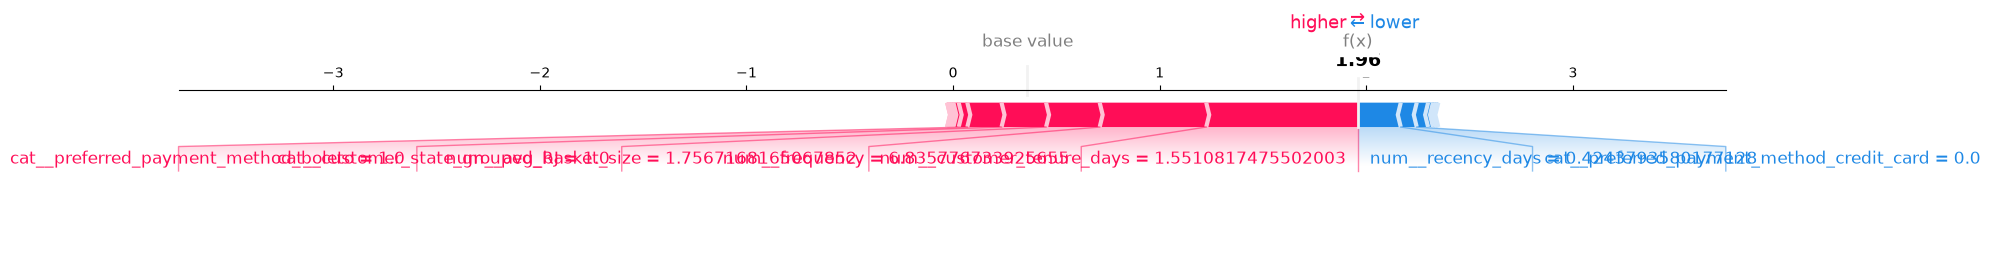

In [11]:
clv_preds = clv_predict_fn(explain_c)
top_value_idx = np.argmax(clv_preds)

print(f'Predicted future revenue for this customer: R${clv_preds[top_value_idx]:.2f}')
print(explain_c_raw.iloc[top_value_idx])  # raw (human-readable) feature values

shap.plots.force(clv_shap_values[top_value_idx], matplotlib=True, show=False)
plt.tight_layout()
plt.show()

## Why was this product recommended?

In [12]:
products = rec_artifacts['products']
prod_idx = rec_artifacts['prod_idx']
customers_rec = rec_artifacts['customers']
cust_idx = rec_artifacts['cust_idx']
content_matrix = rec_artifacts['content_matrix']
item_similarity = rec_artifacts['item_similarity']
product_meta = rec_artifacts['product_meta']
train_purchased = rec_artifacts['train_purchased']

from sklearn.metrics.pairwise import cosine_similarity

def minmax(arr):
    lo, hi = arr.min(), arr.max()
    return np.zeros_like(arr) if hi - lo < 1e-9 else (arr - lo) / (hi - lo)

def explain_recommendation(customer_id, recommended_product_id, content_weight=0.5, top_n_reasons=3):
    if customer_id not in cust_idx or recommended_product_id not in prod_idx:
        print('Customer or product not in the recommendation catalog (filtered out in Phase 8).')
        return

    purchased = train_purchased.get(customer_id, set())
    rec_idx = prod_idx[recommended_product_id]

    # Content contribution
    purchased_idxs = [prod_idx[p] for p in purchased if p in prod_idx]
    profile = content_matrix[purchased_idxs].mean(axis=0, keepdims=True) if purchased_idxs \
        else np.zeros((1, content_matrix.shape[1]))
    content_score = cosine_similarity(profile, content_matrix[[rec_idx]])[0, 0]

    # CF contribution, broken down by which past purchase contributed most
    cf_contributions = []
    for p in purchased:
        if p not in prod_idx:
            continue
        sim = item_similarity[prod_idx[p], rec_idx]
        cf_contributions.append((p, sim))
    cf_contributions.sort(key=lambda x: -x[1])
    cf_score = sum(sim for _, sim in cf_contributions)

    combined = content_weight * content_score + (1 - content_weight) * cf_score  # approximate, unnormalized

    rec_category = product_meta.loc[recommended_product_id, 'category']
    print(f'Recommended product: {recommended_product_id}  (category: {rec_category})')
    print(f'  Content-based similarity to purchase profile: {content_score:.3f}')
    print(f'  Collaborative-filtering score (sum of item-item similarity): {cf_score:.3f}')
    print()
    print(f'  Top {top_n_reasons} past purchases driving the CF signal:')
    for p, sim in cf_contributions[:top_n_reasons]:
        cat = product_meta.loc[p, 'category'] if p in product_meta.index else 'unknown'
        print(f'    - {p} (category: {cat})  similarity={sim:.3f}')

# Example: explain the top hybrid recommendation for a sample customer
sample_customer = next(c for c in customers_rec if len(train_purchased.get(c, set())) > 0)
purchased = train_purchased[sample_customer]
purchased_idxs = [prod_idx[p] for p in purchased]
profile = content_matrix[purchased_idxs].mean(axis=0, keepdims=True)
content_scores = cosine_similarity(profile, content_matrix)[0]

c_idx = cust_idx[sample_customer]
user_vector = np.zeros(len(products))
for p in purchased:
    user_vector[prod_idx[p]] = 1
cf_scores = user_vector @ item_similarity

combined_scores = 0.5 * minmax(content_scores) + 0.5 * minmax(cf_scores)
for p in purchased:
    combined_scores[prod_idx[p]] = -np.inf  # exclude already-purchased
top_recommendation = products[np.argmax(combined_scores)]

explain_recommendation(sample_customer, top_recommendation)

Recommended product: 08574b074924071f4e201e151b152b4e  (category: garden_tools)
  Content-based similarity to purchase profile: 0.994
  Collaborative-filtering score (sum of item-item similarity): 0.000

  Top 3 past purchases driving the CF signal:
    - c4baedd846ed09b85f78a781b522f126 (category: garden_tools)  similarity=0.000
